# Markets near all-time highs: indicators & cash allocation
**Generated:** 2026-11-24 · companion to `research/market_highs_cash_allocation.md`

This notebook reproduces every number in the report from the `market_timing` package:
1. Data panel (S&P 500 1871–today, point-in-time).
2. Which indicators actually predict returns / drawdowns (in-sample, out-of-sample, AUC).
3. What happens after the market is at or near its all-time high, by valuation.
4. Backtests of cash rules within a 0–40% cash envelope, vs a static mix holding the *same average cash*.
5. Cycle phases, global robustness, and today's dashboard.

> Educational research, not financial advice. Past relationships can break.


In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick
from market_timing import data as D, indicators as I, evaluate as E, allocation as A, backtest as B
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)

# Reference palette (validated categorical slots 1-3; text/surface tokens)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, SURF = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2.0,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 110,
})

df_all = D.us_monthly()
df = df_all[df_all["complete"]]
ind = I.compute_all(df)
print(f"Panel {df.index[0].date()} -> {df.index[-1].date()} ({len(df)} months); latest partial month: {df_all.index[-1].date()}")
df.tail(3)

Panel 1871-01-31 -> 2026-10-31 (1870 months); latest partial month: 2026-11-30


,price,ret,rf,cpi_pit,earn_pit,div,gs10,tb3,baa,aaa,unrate,sahm,cfnai,nfci,vix,mcap_gdp,aiae,usrec,ma_200d,rv_1m,ath,high_52w,complete
date,,,,,,,,,,,,,,,,,,,,,,,
2026-08-31,7686.14,0.029,0.003,331.569,229.896,82.660,4.68,3.72,6.32,5.88,4.1,-0.03,0.13,-0.539,14.92,2.195,0.443,0.0,7122.918,0.105,7798.99,7798.99,True
2026-09-30,7651.54,-0.008,0.003,332.882,249.203,83.089,4.99,3.94,6.47,6.03,4.1,-0.07,-0.13,-0.547,16.34,2.550,0.479,0.0,7217.092,0.108,7798.99,7798.99,True
2026-10-31,7580.07,-0.009,0.003,335.041,249.203,83.141,5.13,4.05,6.59,6.12,4.2,0.00,0.05,-0.507,19.42,2.550,0.479,0.0,7309.757,0.115,7818.93,7818.93,True


## 1. The market relative to its all-time high
Shaded bands are NBER recessions (ex-post dates, shown for context only, never used as a signal).

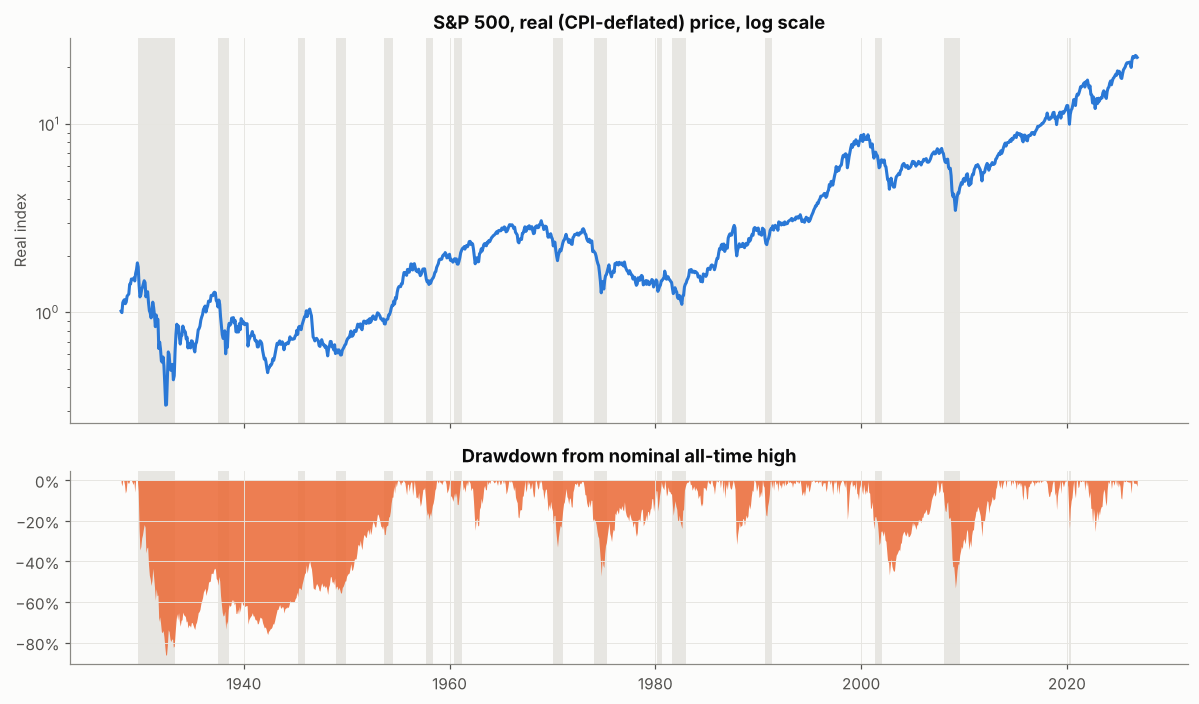

Share of months since 1928 within 2% of the ATH: 23%; within 5%: 36%


In [2]:
def shade_recessions(ax, s):
    rec = df["usrec"].reindex(s.index).fillna(0)
    on = rec.diff().fillna(rec.iloc[0]) == 1; off = rec.diff() == -1
    for a, b in zip(rec.index[on], list(rec.index[off]) + [rec.index[-1]] * (on.sum() - off.sum())):
        ax.axvspan(a, b, color="#d9d8d2", alpha=0.6, lw=0)

sl = slice("1928", None)
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
real = (df["price"] / df["cpi_pit"])[sl]
shade_recessions(ax[0], real); ax[0].plot(real.index, real, color=C1)
ax[0].set_yscale("log"); ax[0].set_title("S&P 500, real (CPI-deflated) price, log scale"); ax[0].set_ylabel("Real index")
dd = ind["drawdown_from_ath"][sl]
shade_recessions(ax[1], dd); ax[1].fill_between(dd.index, dd, 0, color=C2, alpha=0.85, lw=0)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set_title("Drawdown from nominal all-time high")
plt.tight_layout(); plt.show()
print(f"Share of months since 1928 within 2% of the ATH: {(dd >= -0.02).mean():.0%}; within 5%: {(dd >= -0.05).mean():.0%}")

## 2. Indicator scorecard
* `beta/t/R2` – in-sample predictive regression of forward excess log returns (Newey-West t).
* `R2oos` – Campbell-Thompson out-of-sample R² (expanding window from 1950, sign-restricted); `CW_p` – Clark-West p-value.
* `AUC_dd20_12m` – how well the signal (oriented so high = risky) flags a ≥20% drawdown within 12 months (0.5 = coin flip); `hit_top` – drawdown frequency when the signal is in its riskiest quintile / on, vs `base_rate`.

In [3]:
score = E.evaluate_signals(df, ind)
score.drop(columns=["first"]).sort_values(["family", "AUC_dd20_12m"], ascending=[True, False])

,family,beta_1m,t_1m,R2_1m,R2oos_1m,CW_p_1m,beta_12m,t_12m,R2_12m,R2oos_12m,CW_p_12m,AUC_dd20_12m,hit_top,base_rate,n
signal,,,,,,,,,,,,,,,
nearness_52w,ATH proximity,1.280e-02,0.364,6.280e-04,-7.931e-04,0.368,0.010,0.037,2.575e-05,-1.023e-02,0.749,0.654,0.323,0.171,1174
near_ath,ATH proximity,-2.214e-03,-0.782,3.067e-04,2.379e-04,0.241,-0.014,-0.639,8.897e-04,-8.704e-03,0.432,0.473,0.137,0.171,1174
nearness_ath,ATH proximity,-5.695e-03,-0.530,5.937e-04,-4.415e-03,0.905,-0.109,-1.302,1.534e-02,-4.729e-02,0.565,0.413,0.132,0.171,1174
curve_inverted_12m,Macro,-9.049e-03,-1.855,4.950e-03,4.129e-03,0.031,-0.084,-1.714,3.016e-02,2.849e-02,0.036,0.646,0.359,0.171,1174
credit_spread,Macro,1.665e-03,0.262,4.443e-04,-1.132e-03,0.691,0.023,0.663,5.994e-03,-1.396e-02,0.765,0.628,0.251,0.171,1174
nfci,Macro,-2.335e-03,-0.909,2.634e-03,1.498e-03,0.187,-0.007,-0.385,2.105e-03,-3.548e-03,0.779,0.599,0.205,0.129,657
term_spread,Macro,2.104e-03,1.400,2.269e-03,7.593e-04,0.095,0.031,2.348,3.526e-02,-1.326e-02,0.036,0.598,0.322,0.171,1174
credit_widening,Macro,-1.667e-03,-0.455,2.322e-04,-2.234e-03,0.751,-0.019,-0.691,2.024e-03,-3.649e-02,0.736,0.552,0.210,0.171,1174
macro_flag,Macro,2.974e-04,0.084,7.341e-06,-2.464e-03,0.892,-0.003,-0.109,5.577e-05,-3.184e-02,0.929,0.535,0.197,0.171,1174


## 3. What happens after all-time highs?
Mean forward excess return (12/36/60-month figures annualised) and the probability of a ≥20% drawdown within 12 months, by distance from the ATH at month end, split by the composite valuation percentile (terciles of CAPE & excess-CAPE-yield percentiles). Sample 1928–today; overlapping windows, so treat differences of a few % as noise.

,bucket,months,share,fwd_1m,fwd_3m,fwd_12m,pct_neg_12m,fwd_36m,fwd_60m,p_dd20_12m
0,At ATH (0%),67,0.056,0.002,-0.003,0.038,0.292,-0.005,0.023,0.154
1,0 to -2%,205,0.173,0.004,0.021,0.056,0.315,0.054,0.061,0.132
2,-2 to -5%,154,0.130,0.009,0.011,0.049,0.359,0.046,0.051,0.131
3,-5 to -10%,144,0.121,0.006,0.017,0.032,0.343,0.036,0.049,0.140
4,-10 to -20%,187,0.158,0.003,0.014,0.071,0.278,0.062,0.056,0.134
5,Below -20%,429,0.362,0.006,0.019,0.081,0.261,0.090,0.089,0.233


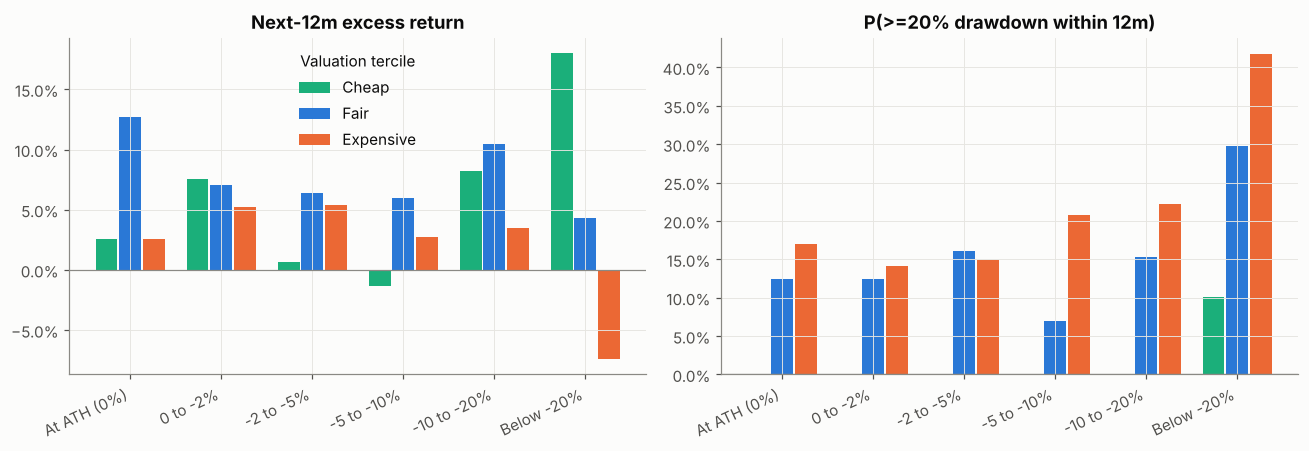

,group,bucket,months,share,fwd_1m,fwd_3m,fwd_12m,pct_neg_12m,fwd_36m,fwd_60m,p_dd20_12m
6,Cheap,At ATH (0%),4,0.013,-8.774e-03,-4.134e-02,0.025,0.500,0.060,0.057,0.000
7,Cheap,0 to -2%,9,0.030,2.017e-02,5.486e-02,0.075,0.333,0.084,0.066,0.000
8,Cheap,-2 to -5%,21,0.069,8.302e-03,1.923e-02,0.006,0.524,0.078,0.062,0.000
9,Cheap,-5 to -10%,18,0.059,-1.717e-02,-2.633e-02,-0.013,0.389,0.054,0.066,0.000
10,Cheap,-10 to -20%,56,0.184,4.301e-03,1.127e-02,0.083,0.321,0.063,0.065,0.000
11,Cheap,Below -20%,197,0.646,1.413e-02,4.086e-02,0.180,0.112,0.149,0.135,0.102
12,Fair,At ATH (0%),8,0.025,1.359e-02,-1.621e-03,0.127,0.125,0.059,0.077,0.125
13,Fair,0 to -2%,32,0.102,7.142e-03,4.523e-02,0.070,0.406,0.022,0.038,0.125
14,Fair,-2 to -5%,31,0.099,1.620e-02,3.288e-02,0.064,0.419,0.044,0.051,0.161
15,Fair,-5 to -10%,43,0.137,9.907e-03,1.866e-02,0.060,0.326,0.051,0.063,0.070


In [4]:
ath = E.ath_bucket_table(df, ind["drawdown_from_ath"], split=ind["valuation_pct"])
display(ath[ath.group == "All"].drop(columns="group"))
piv = ath[ath.group != "All"].pivot(index="bucket", columns="group", values="fwd_12m").reindex([b[0] for b in E.ATH_BUCKETS])
pdd = ath[ath.group != "All"].pivot(index="bucket", columns="group", values="p_dd20_12m").reindex(piv.index)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, tab, title in [(axs[0], piv, "Next-12m excess return"), (axs[1], pdd, "P(>=20% drawdown within 12m)")]:
    x = np.arange(len(tab)); w = 0.26
    for j, (g, col) in enumerate(zip(["Cheap", "Fair", "Expensive"], [C3, C1, C2])):
        ax.bar(x + (j - 1) * w, tab[g], w - 0.02, color=col, label=g)
    ax.set_xticks(x); ax.set_xticklabels(tab.index, rotation=25, ha="right"); ax.set_title(title)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.axhline(0, color=MUTED, lw=0.8)
axs[0].legend(title="Valuation tercile"); plt.tight_layout(); plt.show()
ath[ath.group != "All"]

## 4. Valuation regime: CAPE and excess CAPE yield
Expanding-window percentiles (no look-ahead). The strategic cash layer ramps from 0% at the 60th to 20% at the 95th composite valuation percentile.

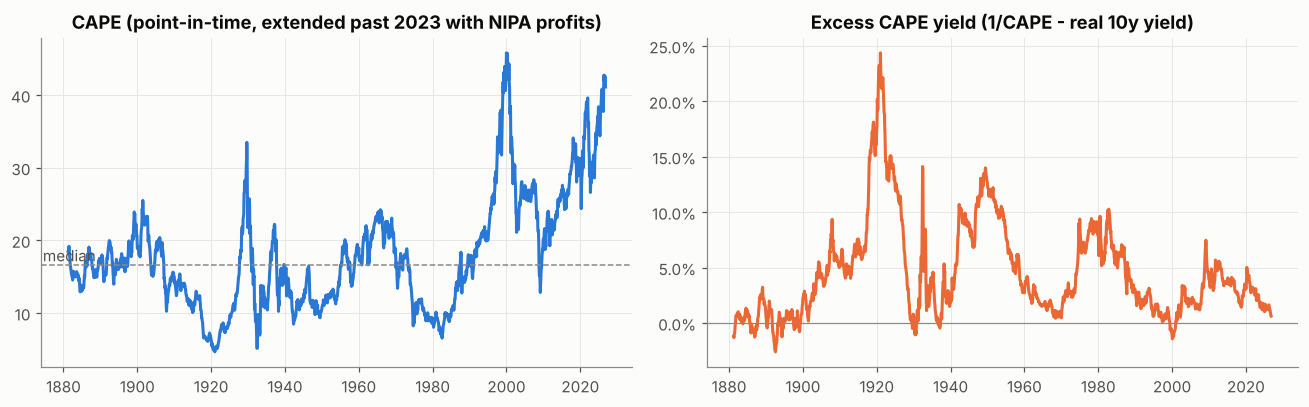

,cape,cape_pct,excess_cape_yield,excess_cape_yield_pct,mcap_gdp_pct,aiae_pct,valuation_pct
date,,,,,,,
2026-08-31,42.629,0.993,0.009,0.177,0.992,0.992,0.908
2026-09-30,42.018,0.991,0.007,0.149,0.999,0.999,0.921
2026-10-31,41.114,0.986,0.006,0.144,0.999,0.999,0.921


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ind["cape"].index, ind["cape"], color=C1); ax[0].set_title("CAPE (point-in-time, extended past 2023 with NIPA profits)")
ax[0].axhline(ind["cape"].median(), color=MUTED, ls="--", lw=1); ax[0].annotate("median", (ind.index[40], ind["cape"].median()), color=INK2, va="bottom")
ax[1].plot(ind["excess_cape_yield"].index, ind["excess_cape_yield"], color=C2); ax[1].set_title("Excess CAPE yield (1/CAPE - real 10y yield)")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].axhline(0, color=MUTED, lw=0.8)
plt.tight_layout(); plt.show()
ind[["cape", "cape_pct", "excess_cape_yield", "excess_cape_yield_pct", "mcap_gdp_pct", "aiae_pct", "valuation_pct"]].dropna(how="all").tail(3)

## 5. Backtests (0–40% cash, monthly, 5pp no-trade band, 10bp costs, cash earns T-bills)
`Matched_*` = a static mix holding the strategy's *average* cash every month. Beating buy-and-hold on risk is trivial with cash; beating the matched mix is the real test. `composite_walkforward` re-selects the composite parameters each decade from 1960 using only prior data.

In [6]:
study = B.run_study(n_boot=1000, save=True)
cols = ["CAGR", "Vol", "Sharpe", "MaxDD", "Calmar", "Ulcer", "AvgCash", "Turnover/yr", "Matched_CAGR", "Matched_Sharpe", "Matched_MaxDD", "dCAGR_vs_matched", "dSharpe_vs_matched", "DownCapture"]
print("Full sample 1930-today"); display(study["full"][cols])
print("1960-today (incl. walk-forward)"); display(study["post1960"][cols])

Full sample 1930-today


,CAGR,Vol,Sharpe,MaxDD,Calmar,Ulcer,AvgCash,Turnover/yr,Matched_CAGR,Matched_Sharpe,Matched_MaxDD,dCAGR_vs_matched,dSharpe_vs_matched,DownCapture
buy_hold,0.101,0.183,0.440,-0.794,0.127,17.937,0.000,0.000,NaN,NaN,NaN,NaN,NaN,1.000
valuation_only,0.098,0.166,0.449,-0.740,0.132,14.145,0.137,0.105,0.095,0.446,-0.732,0.003,0.003,0.856
faber_sma10,0.102,0.143,0.529,-0.582,0.176,12.043,0.131,0.601,0.095,0.443,-0.735,0.008,0.086,0.782
trend_only,0.104,0.145,0.532,-0.582,0.178,12.576,0.125,0.382,0.095,0.442,-0.739,0.009,0.089,0.790
growth_trend,0.106,0.164,0.498,-0.676,0.156,14.627,0.058,0.231,0.100,0.446,-0.764,0.006,0.052,0.885
bank_gains,0.099,0.180,0.436,-0.794,0.125,17.578,0.036,0.033,0.101,0.446,-0.775,-0.002,-0.010,0.970
composite,0.102,0.161,0.483,-0.694,0.146,14.207,0.097,0.207,0.097,0.444,-0.749,0.005,0.039,0.865
composite_volcap,0.101,0.154,0.491,-0.663,0.152,13.871,0.110,0.273,0.097,0.448,-0.743,0.004,0.043,0.841
combination_forecast,0.088,0.160,0.407,-0.794,0.111,16.731,0.181,0.146,0.092,0.445,-0.710,-0.004,-0.038,0.815


1960-today (incl. walk-forward)


,CAGR,Vol,Sharpe,MaxDD,Calmar,Ulcer,AvgCash,Turnover/yr,Matched_CAGR,Matched_Sharpe,Matched_MaxDD,dCAGR_vs_matched,dSharpe_vs_matched,DownCapture
buy_hold,0.108,0.153,0.469,-0.503,0.214,12.295,0.000,0.000,NaN,NaN,NaN,NaN,NaN,1.000
valuation_only,0.100,0.131,0.472,-0.465,0.216,9.149,0.177,0.099,0.099,0.470,-0.429,0.002,0.002,0.808
faber_sma10,0.106,0.126,0.523,-0.338,0.313,8.352,0.118,0.604,0.103,0.472,-0.454,0.003,0.052,0.804
trend_only,0.109,0.129,0.540,-0.340,0.321,8.358,0.110,0.366,0.103,0.473,-0.464,0.006,0.067,0.809
growth_trend,0.112,0.138,0.531,-0.356,0.314,8.901,0.062,0.247,0.106,0.468,-0.485,0.006,0.062,0.872
bank_gains,0.106,0.148,0.465,-0.490,0.215,11.521,0.052,0.048,0.107,0.469,-0.500,-0.001,-0.004,0.951
composite,0.107,0.134,0.510,-0.413,0.259,9.056,0.107,0.214,0.103,0.473,-0.465,0.004,0.037,0.850
composite_volcap,0.106,0.131,0.508,-0.391,0.270,9.053,0.115,0.265,0.103,0.475,-0.452,0.002,0.033,0.837
combination_forecast,0.094,0.118,0.462,-0.478,0.197,9.987,0.219,0.166,0.097,0.473,-0.413,-0.003,-0.011,0.735
composite_walkforward,0.106,0.129,0.520,-0.364,0.292,8.479,0.130,0.265,0.102,0.473,-0.452,0.004,0.047,0.813


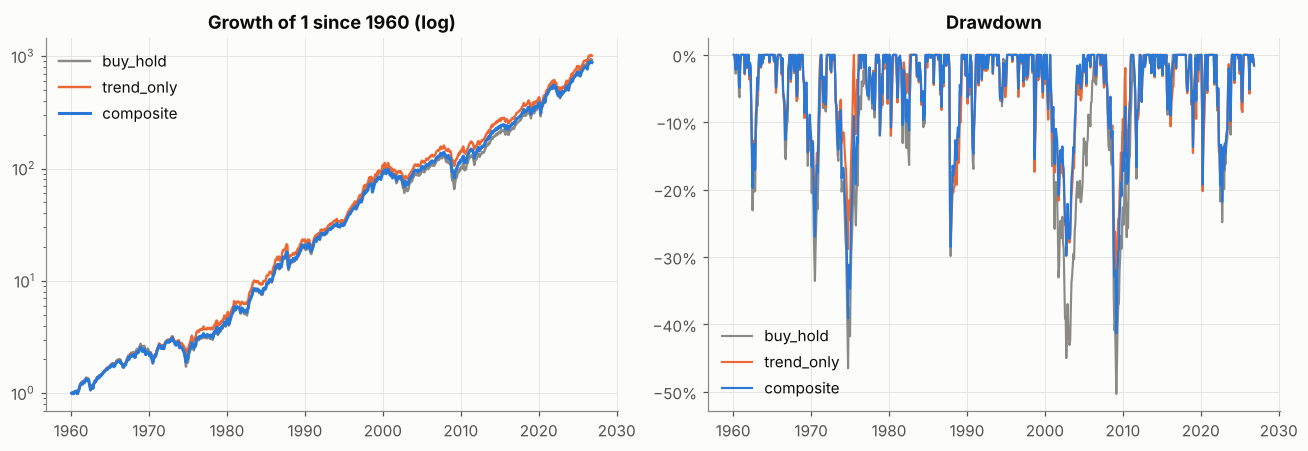

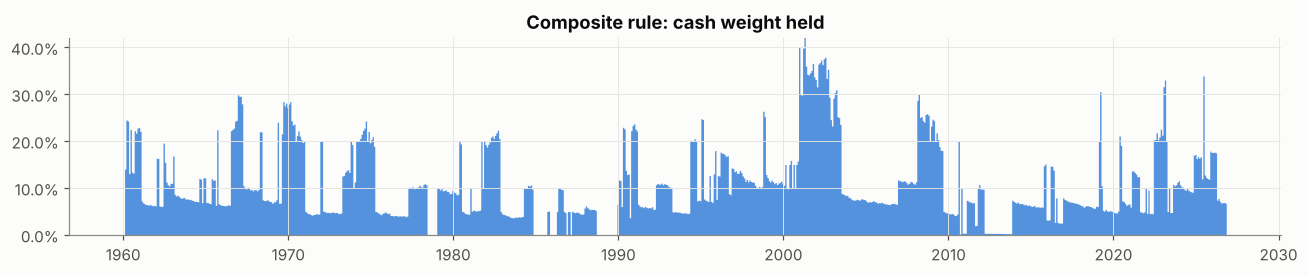

In [7]:
eqc = study["equity_curves"].loc["1960":]
eqc = eqc / eqc.iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, col in [("buy_hold", MUTED), ("trend_only", C2), ("composite", C1)]:
    ax[0].plot(eqc.index, eqc[name], color=col, label=name, lw=2 if name == "composite" else 1.6)
    ddc = eqc[name] / eqc[name].cummax() - 1
    ax[1].plot(ddc.index, ddc, color=col, label=name, lw=1.4)
ax[0].set_yscale("log"); ax[0].set_title("Growth of 1 since 1960 (log)"); ax[0].legend()
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set_title("Drawdown"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()
cp = study["cash_paths"]["composite"].loc["1960":]
fig, ax = plt.subplots(figsize=(12, 2.6)); ax.fill_between(cp.index, cp, 0, step="post", color=C1, alpha=0.8, lw=0)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, 0.42); ax.set_title("Composite rule: cash weight held"); plt.tight_layout(); plt.show()

In [8]:
print("Sub-periods"); display(study["subperiods"][["period", "CAGR", "Sharpe", "MaxDD", "AvgCash", "dCAGR_vs_matched", "dSharpe_vs_matched"]])
print("Bootstrap (stationary, 12m blocks) of Sharpe difference vs matched static; deflated Sharpe of active returns across all trials")
display(study["bootstrap"])
print("Walk-forward parameter choices"); display(study["walkforward_params"])

Sub-periods


,period,CAGR,Sharpe,MaxDD,AvgCash,dCAGR_vs_matched,dSharpe_vs_matched
buy_hold,1930-1949,0.042,0.268,-0.794,0.000,NaN,NaN
valuation_only,1930-1949,0.052,0.304,-0.740,0.053,8.877e-03,0.031
faber_sma10,1930-1949,0.060,0.366,-0.582,0.196,1.716e-02,0.091
trend_only,1930-1949,0.055,0.342,-0.582,0.197,1.247e-02,0.067
growth_trend,1930-1949,0.053,0.312,-0.676,0.048,9.514e-03,0.039
bank_gains,1930-1949,0.042,0.268,-0.794,0.000,0.000e+00,0.000
composite,1930-1949,0.053,0.311,-0.694,0.077,8.573e-03,0.035
composite_volcap,1930-1949,0.051,0.312,-0.663,0.113,5.645e-03,0.030
combination_forecast,1930-1949,0.030,0.224,-0.794,0.135,-1.288e-02,-0.050
buy_hold,1950-1989,0.122,0.514,-0.465,0.000,NaN,NaN


Bootstrap (stationary, 12m blocks) of Sharpe difference vs matched static; deflated Sharpe of active returns across all trials


,sharpe_diff,ci_lo,ci_hi,p_le_0,active_IR_ann,deflated_sharpe_prob
valuation_only,0.003,-0.028,0.039,0.386,0.146,3.870e-01
faber_sma10,0.087,0.030,0.144,0.000,0.102,2.406e-01
trend_only,0.089,0.035,0.144,0.001,0.140,3.693e-01
growth_trend,0.052,0.011,0.097,0.003,0.100,2.387e-01
bank_gains,-0.010,-0.024,0.005,0.884,-0.148,9.330e-04
composite,0.039,0.014,0.067,0.002,0.210,6.382e-01
composite_volcap,0.043,0.015,0.076,0.004,0.078,1.747e-01
combination_forecast,-0.038,-0.080,0.020,0.907,-0.061,1.046e-02
composite_walkforward,0.053,0.007,0.101,0.011,0.169,4.814e-01


Walk-forward parameter choices


,from,params,train_Sharpe
0,1960,s0.2_v0.5_t0.3_vt,0.505
1,1970,s0.2_v0.5_t0.3_vt,0.474
2,1980,s0.2_v0.5_t0.3_vt,0.416
3,1990,s0.2_v0.5_t0.3_vt,0.435
4,2000,s0.2_v0.5_t0.3_vt,0.481
5,2010,s0.2_v0.5_t0.3_vt,0.440
6,2020,s0.2_v0.5_t0.3_vt,0.484


## 6. Cycle phases and global robustness
Phase is classified point-in-time (see `allocation.cycle_phase`). The global check reuses the same logic on Ken French country/region indices (1985+, dividend-yield valuation, term-spread inversion as the macro leg).

In [9]:
display(study["phases"])
display(study["global"][["region", "CAGR", "Sharpe", "MaxDD", "AvgCash", "Matched_MaxDD", "dCAGR_vs_matched", "dSharpe_vs_matched"]])

,months,ann_excess_from_1m,fwd12_excess,vol_1m,p_dd20_12m
phase,,,,,
contraction,165,-0.058,0.036,0.257,0.370
early,308,0.088,0.071,0.156,0.127
late,154,0.068,0.069,0.150,0.110
mid,535,0.086,0.070,0.177,0.129


,region,CAGR,Sharpe,MaxDD,AvgCash,Matched_MaxDD,dCAGR_vs_matched,dSharpe_vs_matched
buy_hold,UK,0.094,0.347,-0.404,0.000,NaN,NaN,NaN
faber_sma10,UK,0.089,0.350,-0.301,0.132,-0.358,-8.260e-04,0.010
valuation_only,UK,0.086,0.327,-0.403,0.186,-0.328,-2.400e-03,-0.024
bank_gains,UK,0.093,0.351,-0.404,0.048,-0.395,9.373e-05,0.005
composite,UK,0.090,0.350,-0.326,0.109,-0.362,-5.194e-04,0.007
buy_hold,Japan,0.063,0.249,-0.591,0.000,NaN,NaN,NaN
faber_sma10,Japan,0.075,0.333,-0.427,0.174,-0.502,1.253e-02,0.075
valuation_only,Japan,0.058,0.229,-0.538,0.090,-0.550,-4.707e-03,-0.022
bank_gains,Japan,0.062,0.246,-0.591,0.019,-0.585,-6.632e-04,-0.002
composite,Japan,0.066,0.272,-0.504,0.081,-0.552,3.330e-03,0.020


## 7. Today's dashboard
Uses the latest (possibly partial) month and the latest *published* value of every input.

In [10]:
from market_timing import signal_today as S
r = S.recommend(portfolio_value=100_000, current_cash=0.0, years_to_need=10)
print(f"As of {r['as_of']} (partial month: {r['partial_month']}), S&P 500 {r['last_price']:,.0f}")
display(r["dashboard"])
print(r["layers"], "| phase:", r["phase"], "| recommended cash:", f"{r['recommended_cash']:.0%}")

As of 2026-11-30 (partial month: True), S&P 500 7,237


,indicator,value,hist_pct,state,note
0,-- ATH proximity --,,,,
1,Drawdown from ATH,-7.4%,63%,ok,near ATH = not a sell signal by itself
2,Months since ATH,6.0,33%,,
3,Price / 52-week high,0.93,35%,ok,low -> trend damage
4,-- Valuation --,,,,
5,CAPE (Shiller P/E10),38.9,98%,RISK,high pct -> lower 10y returns
6,Excess CAPE yield,+0.8%,16%,RISK,low -> equities rich vs bonds
7,Market cap / GDP,2.55,100%,RISK,high pct -> drawdown risk
8,Investor equity allocation,0.48,100%,RISK,high pct -> lower 10y returns
9,Composite valuation pct,0.91,95%,RISK,>= 0.60 starts the strategic layer


{'strategic': 0.08741321571510252, 'tactical': 0.0, 'total': 0.08741321571510252} | phase: mid | recommended cash: 9%
